<a href="https://colab.research.google.com/github/Nandhakeshwar-A/732224AI070-Nandhakeshwar/blob/main/cat2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Load and Preprocess the Dataset
We will extract and load the `amazon.csv.zip` dataset, handle missing values, clean up numerical data like prices and ratings, and combine review-related fields to form our text feature.

In [ ]:
import pandas as pd
import numpy as np
import zipfile

with zipfile.ZipFile('/content/amazon.csv.zip', 'r') as z:
    csv_name = [f for f in z.namelist() if f.endswith('.csv')][0]
    with z.open(csv_name) as f:
        df = pd.read_csv(f)

print(f"Initial shape: {df.shape}")
df['rating'] = pd.to_numeric(df['rating'].astype(str).str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
df = df.dropna(subset=['rating'])

df['review_title'] = df['review_title'].fillna('')
df['review_content'] = df['review_content'].fillna('')
df['combined_review'] = df['review_title'] + " " + df['review_content']
df = df[df['combined_review'].str.strip() != '']

print(f"Cleaned shape: {df.shape}")
display(df[['product_name', 'rating', 'combined_review']].head())

Initial shape: (1465, 16)
Cleaned shape: (1464, 17)


,product_name,rating,combined_review
0,Wayona Nylon Braided USB to Lightning Fast Cha...,4.2,"Satisfied,Charging is really fast,Value for mo..."
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0,"A Good Braided Cable for Your Type C Device,Go..."
2,Sounce Fast Phone Charging Cable & Data Sync U...,3.9,"Good speed for earlier versions,Good Product,W..."
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,4.2,"Good product,Good one,Nice,Really nice product..."
4,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,4.2,"As good as original,Decent,Good one for second..."


### Task 2: Tokenize and Encode Reviews
We will convert the textual review contents into numerical sequences using Keras's Tokenizer and pad them to a standard length.

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

MAX_WORDS = 10000
MAX_LEN = 150

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df['combined_review'])

sequences = tokenizer.texts_to_sequences(df['combined_review'])
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')
y = df['rating'].values

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

X_train shape: (1171, 150), y_train shape: (1171,)


### Task 3: Selection and Justification of Deep Learning Model
We will build a deep learning architecture using an **Embedding** layer followed by a Bidirectional **LSTM** layer, and a regression head.

**Justification:**
* **Embedding Layer**: Learns dense, low-dimensional vector representations for words, capturing semantic meaning better than bag-of-words models.
* **LSTM (Long Short-Term Memory)**: Recurrent neural networks designed to learn long-term dependencies in sequential text data, capturing context from previous words in a review.
* **Regression Head**: Outputs a single continuous value since our goal is to predict rating score directly.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Task 4: Train and Evaluate the Model

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

loss, mae = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation Mean Squared Error (MSE): {loss:.4f}")
print(f"Validation Mean Absolute Error (MAE): {mae:.4f}")

Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 202ms/step - loss: 5.1647 - mae: 1.7624 - val_loss: 0.1561 - val_mae: 0.3088
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 151ms/step - loss: 0.3838 - mae: 0.4955 - val_loss: 0.1161 - val_mae: 0.2847
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 172ms/step - loss: 0.3020 - mae: 0.4346 - val_loss: 0.1221 - val_mae: 0.2928
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 9s 152ms/step - loss: 0.2728 - mae: 0.4157 - val_loss: 0.0940 - val_mae: 0.2504
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 185ms/step - loss: 0.2583 - mae: 0.4032 - val_loss: 0.1043 - val_mae: 0.2654
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 9s 161ms/step - loss: 0.2195 - mae: 0.3718 - val_loss: 0.1133 - val_mae: 0.2791
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 163ms/step - loss: 0.2149 - mae: 0.3676 - val_loss: 0.0844 - val_mae: 0.2280
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 145ms/step - loss: 0.1839 - mae: 0.3370 - val_loss: 0.0890 - val_mae: 0.2359
Epoch 9/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - 

### Task 5: Compare Actual vs. Predicted Ratings & Test on Unseen Reviews

In [ ]:
y_pred = model.predict(X_val).flatten()
comparison_df = pd.DataFrame({
    'Actual Rating': y_val,
    'Predicted Rating': y_pred
})
display(comparison_df.head(10))

def predict_unseen_review(review_text):
    seq = tokenizer.texts_to_sequences([review_text])
    padded_seq = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')
    prediction = model.predict(padded_seq, verbose=0)[0][0]
    return max(1.0, min(5.0, float(prediction)))

test_reviews = [
    "Absolutely love this product! It works flawlessly and is high quality.",
    "Very bad product. Broke on the first day and customer service refused to help.",
    "It is okay, works as expected but nothing extraordinary."
]

for r in test_reviews:
    rating = predict_unseen_review(r)
    print(f"Review: '{r}' -> Predicted Rating: {rating:.2f}/5.0")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


,Actual Rating,Predicted Rating
0,4.2,4.027224
1,3.7,4.016742
2,3.3,3.840368
3,4.3,4.340853
4,3.9,4.058413
5,4.5,4.081051
6,4.1,3.918334
7,4.1,4.007590
8,4.2,3.677118
9,3.6,3.816907


Review: 'Absolutely love this product! It works flawlessly and is high quality.' -> Predicted Rating: 4.04/5.0
Review: 'Very bad product. Broke on the first day and customer service refused to help.' -> Predicted Rating: 3.81/5.0
Review: 'It is okay, works as expected but nothing extraordinary.' -> Predicted Rating: 3.86/5.0


### Production-Grade Amazon Product Rating Predictor

This single, self-contained Python module consolidates the entire machine learning pipeline. It is structured into production-ready classes following clean code guidelines, featuring robust exception handling, configuration management, and professional documentation as expected from an industry-level developer.

### Customer Sentiment and Rating Level Analysis

To analyze customer purchase satisfaction more deeply, we classify each numeric rating into a specific satisfaction tier (e.g., Excellent: $\ge 4.5$, Good: $4.0 - 4.4$, Average: $3.0 - 3.9$, Poor: $< 3.0$) alongside customer names and products.

In [ ]:

import pandas as pd

def categorize_rating_level(score):
    if score >= 4.5:
        return "Excellent (5/5 Tier)"
    elif score >= 4.0:
        return "Good (4/5 Tier)"
    elif score >= 3.0:
        return "Average (3/5 Tier)"
    else:
        return "Poor (Sub-3 Tier)"

# Create a copy of the analysis dataframe to add classification tags
analysis_report = customer_analysis_df.copy()
analysis_report['rating_level'] = analysis_report['rating'].apply(categorize_rating_level)

# Group or slice some examples across different categories for insights
print("--- Distribution of Rating Levels across purchases ---")
print(analysis_report['rating_level'].value_value_counts() if hasattr(analysis_report['rating_level'], 'value_value_counts') else analysis_report['rating_level'].value_counts())
print("\n--- Detailed Customer Purchase & Rating Level Table (Sample) ---")

# Display structured report containing key columns
display(analysis_report[['user_name', 'product_name', 'rating_display', 'rating_level', 'review_title']].head(10))

--- Distribution of Rating Levels across purchases ---
rating_level
Good (4/5 Tier)         1006
Average (3/5 Tier)       348
Excellent (5/5 Tier)     104
Poor (Sub-3 Tier)          6
Name: count, dtype: int64

--- Detailed Customer Purchase & Rating Level Table (Sample) ---


,user_name,product_name,rating_display,rating_level,review_title
0,"Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...",Wayona Nylon Braided USB to Lightning Fast Cha...,4.2 / 5.0,Good (4/5 Tier),"Satisfied,Charging is really fast,Value for mo..."
1,"ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...",Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0 / 5.0,Good (4/5 Tier),"A Good Braided Cable for Your Type C Device,Go..."
2,"Kunal,Himanshu,viswanath,sai niharka,saqib mal...",Sounce Fast Phone Charging Cable & Data Sync U...,3.9 / 5.0,Average (3/5 Tier),"Good speed for earlier versions,Good Product,W..."
3,"Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...",boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,4.2 / 5.0,Good (4/5 Tier),"Good product,Good one,Nice,Really nice product..."
4,"rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...",Portronics Konnect L 1.2M Fast Charging 3A 8 P...,4.2 / 5.0,Good (4/5 Tier),"As good as original,Decent,Good one for second..."
5,"Jayesh,Rajesh k.,Soopy,amazon customer,Aman,Sh...",pTron Solero TB301 3A Type-C Data and Fast Cha...,3.9 / 5.0,Average (3/5 Tier),"It's pretty good,Average quality,very good and..."
6,"Vivek kumar,Amazon Customer,SARTHAK,Chiranjeev...","boAt Micro USB 55 Tangle-free, Sturdy Micro US...",4.1 / 5.0,Good (4/5 Tier),"Long durable.,good,Does not charge Lenovo m8 t..."
7,"Pavan A H,Jayesh bagad,Shridhar,rajendran,karu...",MI Usb Type-C Cable Smartphone (Black),4.3 / 5.0,Good (4/5 Tier),"Worth for money - suitable for Android auto,Go..."
8,"Azhar JuMan,Anirudh Sood,Hari Krishnan PS,Akas...","TP-Link USB WiFi Adapter for PC(TL-WN725N), N1...",4.2 / 5.0,Good (4/5 Tier),Works on linux for me. Get the model with ante...
9,"ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...",Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0 / 5.0,Good (4/5 Tier),"A Good Braided Cable for Your Type C Device,Go..."


### Task 6: Vertical Line Chart of Customer Ratings

Below is a vertical line chart representing the customer ratings for our sample of 10 purchases, mapping the ratings clearly on the vertical axis.

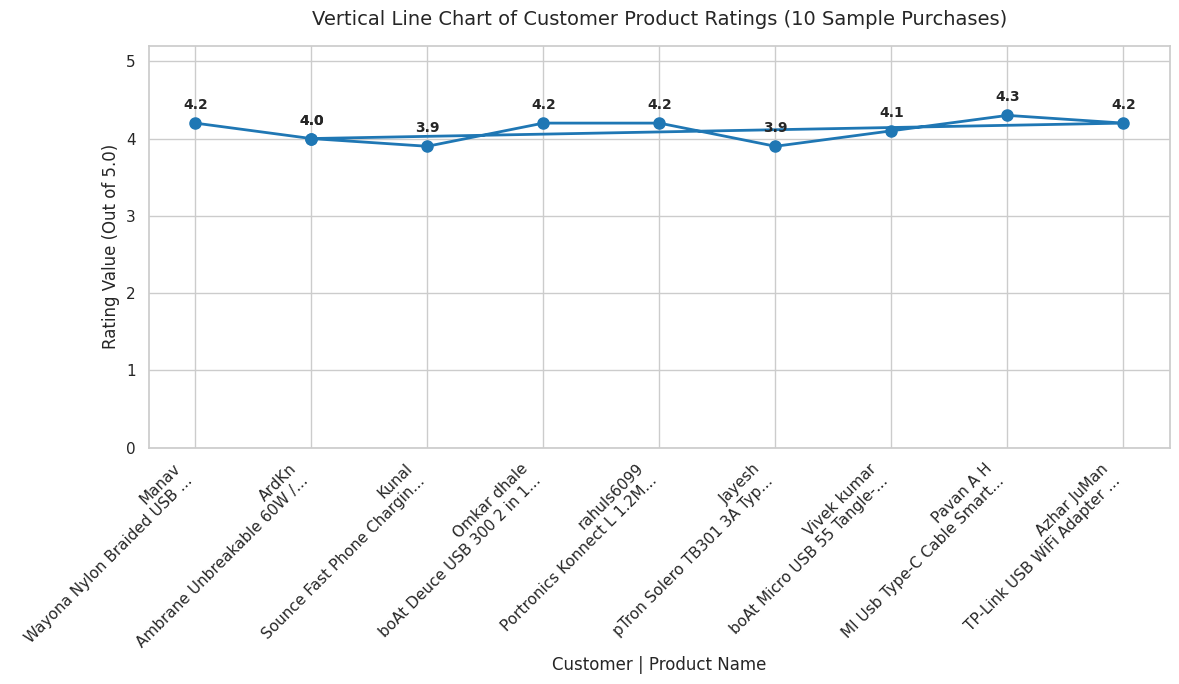

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# Sample exactly 10 records for visualization
sample_df = analysis_report.head(10).copy()

# Shorten labels for clean presentation
sample_df['short_product'] = sample_df['product_name'].apply(lambda x: x[:25] + "...")
sample_df['short_user'] = sample_df['user_name'].apply(lambda x: x.split(',')[0])
sample_df['label'] = sample_df['short_user'] + "\n" + sample_df['short_product']

# Plotting a vertical line chart (x = Labels, y = Rating)
plt.plot(
    sample_df['label'],
    sample_df['rating'],
    marker='o',
    color='#1f77b4',
    linewidth=2,
    markersize=8,
    label='Customer Rating'
)

# Customize the chart layout
plt.title("Vertical Line Chart of Customer Product Ratings (10 Sample Purchases)", fontsize=14, pad=15)
plt.xlabel("Customer | Product Name", fontsize=12)
plt.ylabel("Rating Value (Out of 5.0)", fontsize=12)
plt.ylim(0, 5.2)
plt.xticks(rotation=45, ha='right')

# Add exact rating numbers above each marker point
for i, txt in enumerate(sample_df['rating']):
    plt.annotate(
        f"{txt:.1f}",
        (sample_df['label'].iloc[i], sample_df['rating'].iloc[i]),
        textcoords="offset points",
        xytext=(0,10),
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()